In [1]:
from pystac_client import Client
import geopandas as gpd
import planetary_computer

import odc.stac
import folium
import numpy as np

import rioxarray
import rasterio.features
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
path_to_geojson = "../__geojson__/darney_3_regions.geojson"

## PySTAC, geopandas, planetary_computer, odc

In [3]:
# Load GeoJSON data
gdf = gpd.read_file(path_to_geojson)

# Ensure the GeoDataFrame is in standard WGS84 latitude/longitude coordinates
if gdf.crs != "EPSG:4326":
    gdf = gdf.to_crs("EPSG:4326")

# Get total bounds [xmin, ymin, xmax, ymax] for the STAC search including all polygons
total_bounds = gdf.total_bounds
unary_union = gdf.unary_union

# Search Planetary Computer for Sentinel-1 data
catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=planetary_computer.sign_inplace)
search = catalog.search(
    collections=["sentinel-1-rtc"],
    bbox=total_bounds,
    datetime="2018-06-01/2018-06-30",
    query={"sat:orbit_state": {"eq": "descending"}}
)
items = list(search.item_collection())

# Load raster data clipped to the to union of all polygons
ds = odc.stac.load(
    items,
    bands=["vv", "vh"],
    geopolygon=unary_union,
    crs="EPSG:32631",  
    resolution=10,     
    groupby="solar_day"
).compute()

/tmp/ipykernel_38528/1236350137.py:10: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  unary_union = gdf.unary_union


## Basic Matplotlib

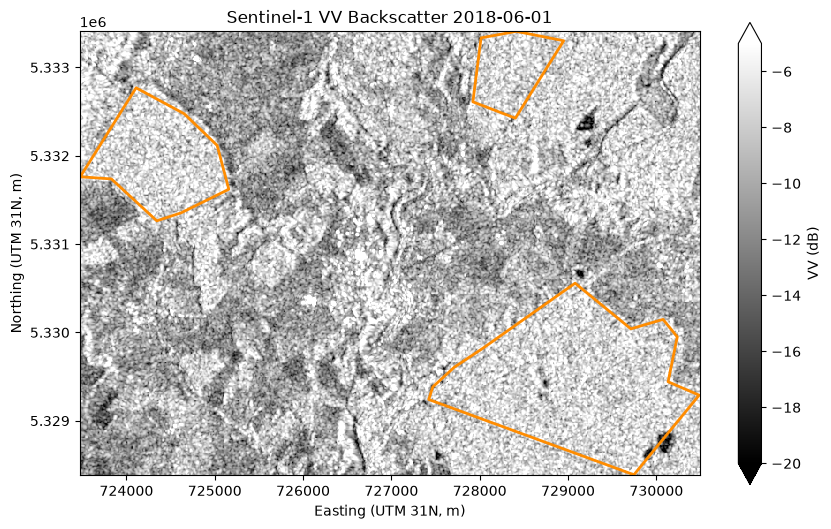

In [4]:
# Get the VV band for the first time step, and log-compress for display
slice_data = ds["vv"].isel(time=0)
slice_data_db = 10.0 * np.log10(slice_data)

fig, ax = plt.subplots(figsize=(10, 10))

# Plot the raster pixels
slice_data_db.plot.imshow(
    ax=ax,
    cmap='gray',
    vmin=-20,
    vmax=-5,
    cbar_kwargs={
            'shrink': 0.6,
            'aspect': 20,
            'label': "VV (dB)"
        }    
)

# Reproject GeoDataFrame to match the raster's CRS (EPSG:32631) for accurate map overlay
gdf_projected = gdf.to_crs("EPSG:32631")

# Overlay the polygons
gdf_projected.plot(
    ax=ax,
    facecolor='none',
    edgecolor='darkorange',
    linewidth=2
)

plt.title(f"Sentinel-1 VV Backscatter {str(slice_data.time.values)[:10]}")
plt.xlabel("Easting (UTM 31N, m)")
plt.ylabel("Northing (UTM 31N, m)")
plt.show()

## Binary mask

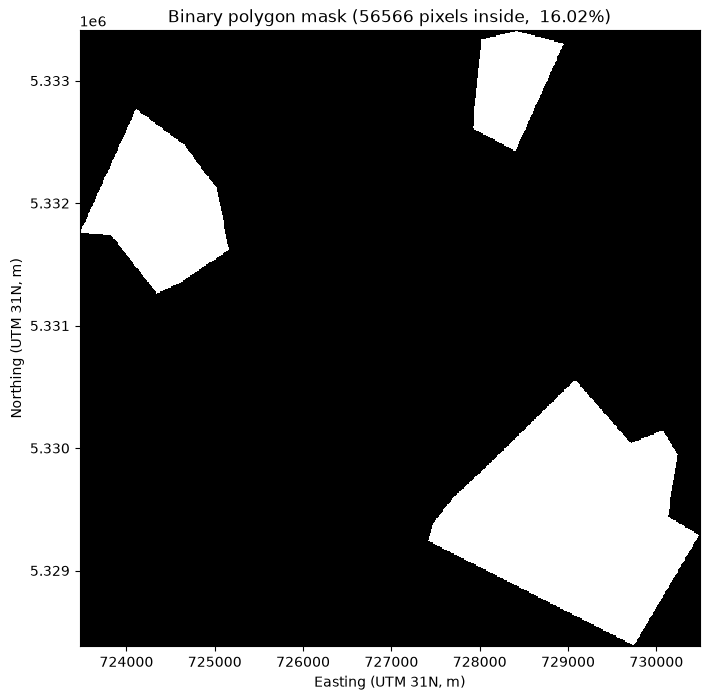

In [5]:
gdf_proj = gdf.to_crs(slice_data_db.rio.crs)

shapes = [(geom, 1) for geom in gdf_proj.geometry]

height, width = slice_data_db.rio.shape
transform = slice_data_db.rio.transform()

mask_array = rasterio.features.rasterize(
    shapes=shapes,
    out_shape=(height, width),
    transform=transform,
    fill=0,
    default_value=1,
    dtype=np.uint8
)

mask_da = xr.DataArray(
    mask_array,
    coords=slice_data_db.coords,
    dims=slice_data_db.dims
)

pixels_inside = int((mask_da == 1).sum().item())
total_pixels = mask_da.size

fig, ax = plt.subplots(figsize=(8, 8))
mask_da.plot.imshow(ax=ax, cmap='gray', add_colorbar=False)
plt.title(f"Binary polygon mask ({pixels_inside} pixels inside,  {pixels_inside/total_pixels:.2%})")
plt.xlabel("Easting (UTM 31N, m)")
plt.ylabel("Northing (UTM 31N, m)")
plt.show()

## Folium

/tmp/ipykernel_38528/1704643172.py:25: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  centroid = gdf.unary_union.centroid



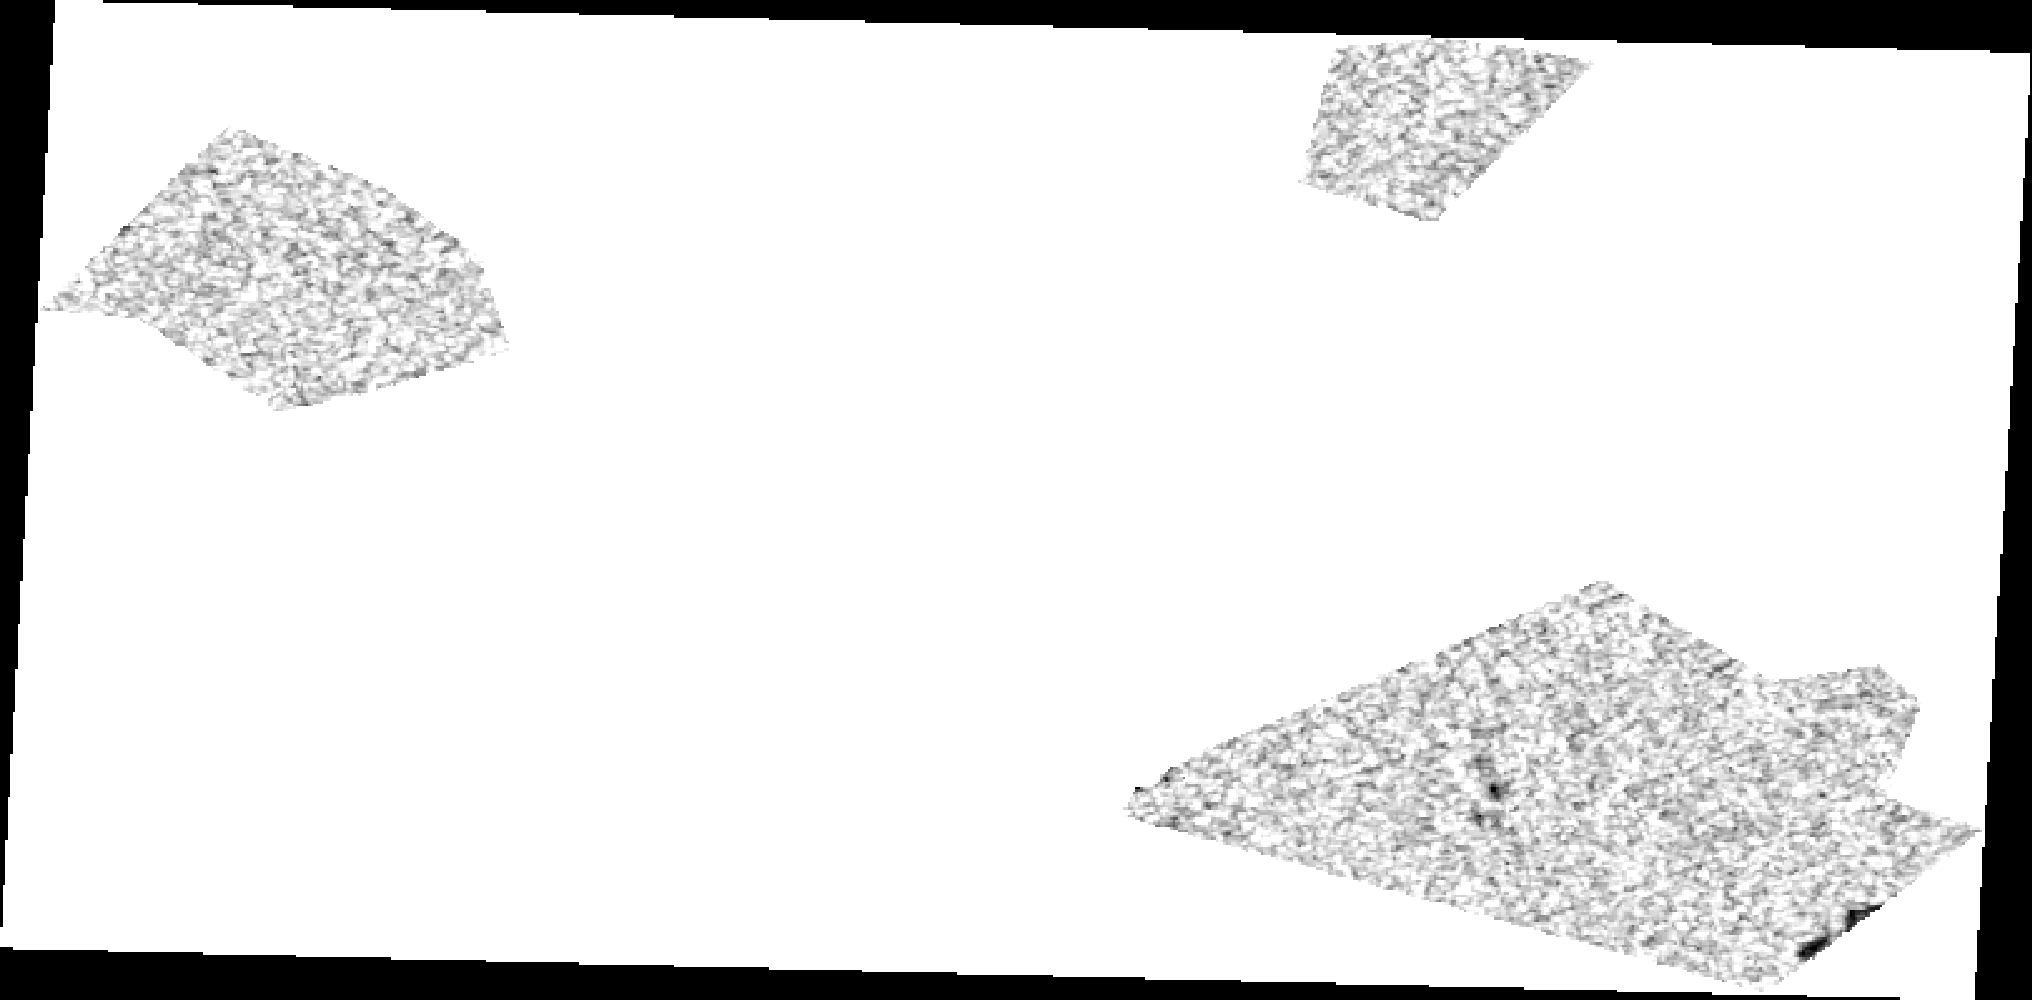

In [9]:
# Render the Sentinel-1 raster to a temporary PNG
masked_slice_db = slice_data_db.where(mask_da == 1)

# Reproject to WGS84 first so pixel coordinates match Leaflet/Folium's WGS84 space natively
masked_wgs84 = masked_slice_db.rio.reproject("EPSG:4326")

# Match figure dimensions to the reprojected raster's actual width/height ratio
ny, nx = masked_wgs84.shape[-2], masked_wgs84.shape[-1]
fig = plt.figure(figsize=(10 * (nx / ny), 10), frameon=False)
ax = plt.Axes(fig, [0., 0., 1., 1.])
fig.add_axes(ax)

masked_wgs84.plot.imshow(ax=ax, cmap='gray', vmin=-20, vmax=-5, add_colorbar=False, add_labels=False)
ax.set_axis_off()
plt.savefig("tmp_overlay.png", pad_inches=0, transparent=True)
plt.close()

# Get the WGS84 bounding box coordinates for the image overlay directly from the reprojected raster
bounds_wgs84 = masked_wgs84.rio.bounds()

# Folium bounds format: [[south, west], [north, east]]
folium_bounds = [[bounds_wgs84[1], bounds_wgs84[0]], [bounds_wgs84[3], bounds_wgs84[2]]]

# Create the interactive Folium map
centroid = gdf.unary_union.centroid
m = folium.Map(location=[centroid.y, centroid.x], zoom_start=12)

# Add a high-resolution satellite background basemap
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri',
    name='Esri Satellite'
).add_to(m)

# Add Sentinel-1 raster as an image layer
folium.raster_layers.ImageOverlay(
    image='tmp_overlay.png',
    bounds=folium_bounds,
    opacity=0.85,
    name='Sentinel-1 VV (dB)'
).add_to(m)

# Add polygons
folium.GeoJson(
    gdf.to_crs("EPSG:4326"),
    name='Darney Polygons',
    style_function=lambda x: {'color': 'darkorange', 'fillColor': 'transparent', 'weight': 2}
).add_to(m)

folium.LayerControl().add_to(m)
m